In [2]:
from pathlib import Path
import torch
from torch import nn, optim
from torch.utils.data import DataLoader, TensorDataset, random_split
from torchvision import datasets
import matplotlib.pyplot as plt

In [3]:
torch.manual_seed(42)
torch.set_num_threads(2)
EPOCHS = 20
PLOT_DIR = Path("output/plots")
PLOT_DIR.mkdir(parents=True, exist_ok=True)

In [4]:
mnist = datasets.MNIST(root="data", train=True, download=True)
images = mnist.data.reshape(-1, 784).float() / 255.0
dataset = TensorDataset(images, mnist.targets)
train_set, val_set = random_split(
    dataset, [50000, 10000], generator=torch.Generator().manual_seed(42))
train_eval_loader = DataLoader(train_set, batch_size=1024)
val_loader = DataLoader(val_set, batch_size=1024)
print(f"Training: {len(train_set)}; validation: {len(val_set)}")

Training: 50000; validation: 10000


In [5]:
def build_model(activation="ReLU", dropout=0.0):
    activations = {"ReLU": nn.ReLU(), "Sigmoid": nn.Sigmoid(), "Tanh": nn.Tanh()}
    return nn.Sequential(
        nn.Linear(784, 128),
        activations[activation],
        nn.Dropout(dropout),
        nn.Linear(128, 10),
    )

criterion = nn.CrossEntropyLoss()

In [ ]:
@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    total_loss, correct = 0.0, 0
    for x, y in loader:
        logits = model(x)
        total_loss += criterion(logits, y).item() * len(y)
        correct += (logits.argmax(dim=1) == y).sum().item()
    return total_loss / len(loader.dataset), correct / len(loader.dataset)

def train_model(optimizer_name="Adam", regularization="None", activation="ReLU"):
    torch.manual_seed(42)  
    model = build_model(activation, dropout=0.3 if regularization == "Dropout" else 0.0)
    if optimizer_name == "Batch GD":
        optimizer = optim.SGD(model.parameters(), lr=0.2)
    elif optimizer_name == "SGD":
        optimizer = optim.SGD(model.parameters(), lr=0.05)
    elif optimizer_name == "Momentum":
        optimizer = optim.SGD(model.parameters(), lr=0.05, momentum=0.9)
    else:
        optimizer = optim.Adam(model.parameters(), lr=0.001,
                               weight_decay=1e-4 if regularization == "L2" else 0.0)
    batch_size = len(train_set) if optimizer_name == "Batch GD" else 256
    loader = DataLoader(train_set, batch_size=batch_size, shuffle=True,
                        generator=torch.Generator().manual_seed(42))
    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    for epoch in range(EPOCHS):
        model.train()
        for x, y in loader:
            optimizer.zero_grad()
            loss = criterion(model(x), y)
            if regularization == "L1":
                loss = loss + 1e-5 * sum(p.abs().sum() for p in model.parameters())
            loss.backward()
            optimizer.step()
        train_loss, train_acc = evaluate(model, train_eval_loader)
        val_loss, val_acc = evaluate(model, val_loader)
        for key, value in zip(history, [train_loss, val_loss, train_acc, val_acc]):
            history[key].append(value)

    weights = torch.cat([p.detach().flatten() for p in model.parameters() if p.ndim > 1])
    history["weight_norm"] = weights.norm().item()
    history["near_zero_pct"] = 100 * (weights.abs() < 0.001).float().mean().item()
    print(f"{optimizer_name}, {regularization}, {activation}: "
          f"train loss={train_loss:.4f}, val loss={val_loss:.4f}, "
          f"train accuracy={train_acc:.2%}, val accuracy={val_acc:.2%}", flush=True)
    return history

Batch GD, None, ReLU: train loss=1.1849, val loss=1.1877, train accuracy=77.70%, val accuracy=78.25%
SGD, None, ReLU: train loss=0.1774, val loss=0.2023, train accuracy=95.12%, val accuracy=94.21%
Momentum, None, ReLU: train loss=0.0196, val loss=0.0890, train accuracy=99.66%, val accuracy=97.43%
Adam, None, ReLU: train loss=0.0175, val loss=0.0920, train accuracy=99.69%, val accuracy=97.25%


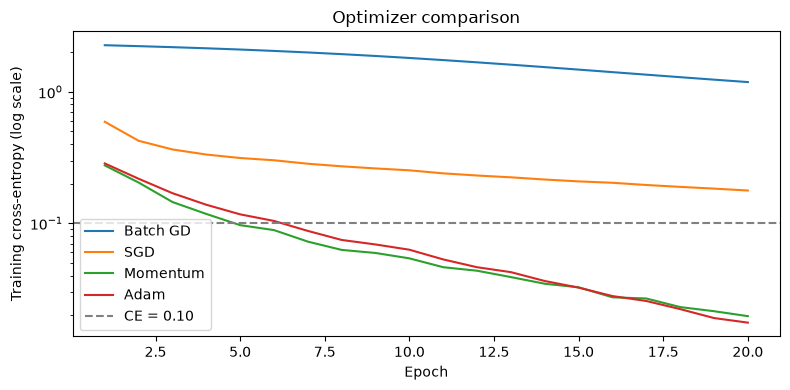

In [7]:
optimizer_results = {}
for name in ["Batch GD", "SGD", "Momentum", "Adam"]:
    optimizer_results[name] = train_model(optimizer_name=name)

plt.figure(figsize=(8, 4))
for name, history in optimizer_results.items():
    plt.plot(range(1, EPOCHS + 1), history["train_loss"], label=name)
plt.axhline(0.10, color="gray", linestyle="--", label="CE = 0.10")
plt.yscale("log")
plt.xlabel("Epoch")
plt.ylabel("Training cross-entropy (log scale)")
plt.title("Optimizer comparison")
plt.legend()
plt.tight_layout()
plt.savefig(PLOT_DIR / "optimization.png", dpi=150)
plt.show()

Adam, L2, ReLU: train loss=0.0257, val loss=0.0858, train accuracy=99.56%, val accuracy=97.28%
Adam, L1, ReLU: train loss=0.0263, val loss=0.0870, train accuracy=99.52%, val accuracy=97.25%
Adam, Dropout, ReLU: train loss=0.0272, val loss=0.0828, train accuracy=99.32%, val accuracy=97.54%


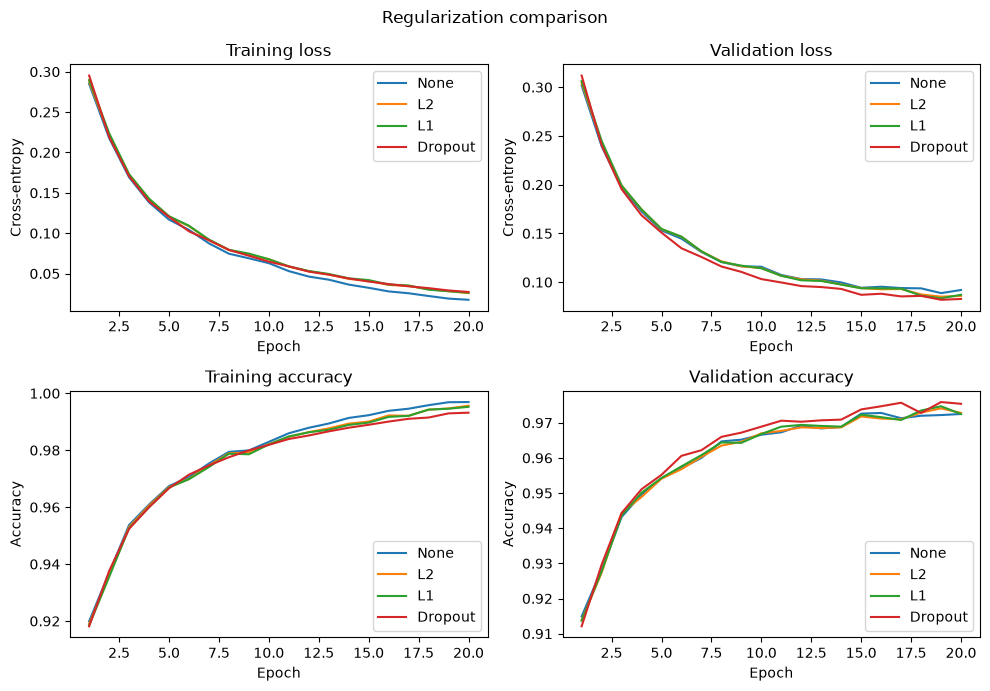

None     | weight L2 norm: 37.22 | near-zero weights (|w| < 0.001): 0.96%
L2       | weight L2 norm: 22.06 | near-zero weights (|w| < 0.001): 21.14%
L1       | weight L2 norm: 22.93 | near-zero weights (|w| < 0.001): 40.72%
Dropout  | weight L2 norm: 36.58 | near-zero weights (|w| < 0.001): 1.05%


In [8]:
regularization_results = {"None": optimizer_results["Adam"]}
for name in ["L2", "L1", "Dropout"]:
    regularization_results[name] = train_model(regularization=name)

def plot_comparison(results, title, filename):
    fig, axes = plt.subplots(2, 2, figsize=(10, 7))
    metrics = ["train_loss", "val_loss", "train_acc", "val_acc"]
    titles = ["Training loss", "Validation loss", "Training accuracy", "Validation accuracy"]
    for ax, metric, panel_title in zip(axes.flat, metrics, titles):
        for name, history in results.items():
            ax.plot(range(1, EPOCHS + 1), history[metric], label=name)
        ax.set_title(panel_title)
        ax.set_xlabel("Epoch")
        ax.set_ylabel("Accuracy" if "acc" in metric else "Cross-entropy")
        ax.legend()
    fig.suptitle(title)
    fig.tight_layout()
    fig.savefig(PLOT_DIR / filename, dpi=150)
    plt.show()

plot_comparison(regularization_results, "Regularization comparison", "regularization.png")
for name, history in regularization_results.items():
    print(f"{name:8s} | weight L2 norm: {history['weight_norm']:.2f} | "
          f"near-zero weights (|w| < 0.001): {history['near_zero_pct']:.2f}%")

Adam, None, Sigmoid: train loss=0.0630, val loss=0.1131, train accuracy=98.38%, val accuracy=96.51%
Adam, None, Tanh: train loss=0.0177, val loss=0.0888, train accuracy=99.79%, val accuracy=97.28%


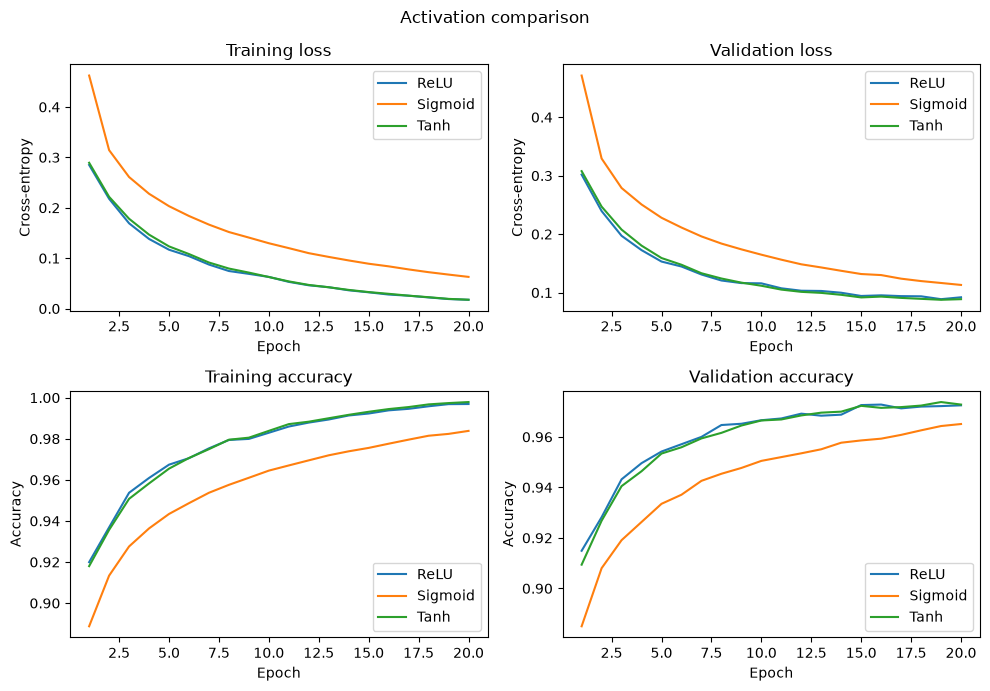

In [9]:
activation_results = {"ReLU": optimizer_results["Adam"]}
for name in ["Sigmoid", "Tanh"]:
    activation_results[name] = train_model(activation=name)
plot_comparison(activation_results, "Activation comparison", "activations.png")